In [3]:
import pandahouse
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import hashlib 
import swifter
import math
from scipy import stats
from scipy.stats import norm, ttest_ind
from tqdm import tqdm
%matplotlib inline

In [4]:
# подключение к Clickhouse
connection = {
    'host': 'http://clickhouse.lab.karpov.courses:8123',
    'password': 'REDACTED',
    'user': 'student',
    'database': 'simulator_20261020'
}

In [5]:
# данные по просмотрам за период A/A-теста
q = """
SELECT views, count() AS users
FROM (SELECT 
    user_id,
    sum(action = 'view') AS views
FROM {db}.feed_actions
WHERE toDate(time) BETWEEN '2026-09-25' AND '2026-10-01'
GROUP BY user_id
)
GROUP BY views
ORDER BY views
"""

views_distribution = pandahouse.read_clickhouse(q, connection=connection)

views_distribution['p'] = views_distribution['users']/views_distribution.users.sum()

views_distribution.head()

,views,users,p
0,1,4,0.000095
1,2,1,0.000024
2,3,4,0.000095
3,4,5,0.000119
4,5,18,0.000429


In [6]:
# данные по ctr за период A/A-теста
q = """
SELECT floor(ctr, 2) AS ctr, count() AS users
FROM (SELECT 
    toDate(time) as dt, 
    user_id,
    sum(action = 'like') / sum(action = 'view') AS ctr
FROM {db}.feed_actions
WHERE toDate(time) BETWEEN '2026-09-25' AND '2026-10-01'
GROUP BY user_id, dt
)
GROUP BY ctr
ORDER BY ctr
"""

ctr_distribution = pandahouse.read_clickhouse(q, connection=connection)

ctr_distribution['p'] = ctr_distribution['users']/ctr_distribution.users.sum()

ctr_distribution.head()

,ctr,users,p
0,0.00,1443,0.016952
1,0.02,48,0.000564
2,0.03,142,0.001668
3,0.04,312,0.003665
4,0.05,727,0.008541


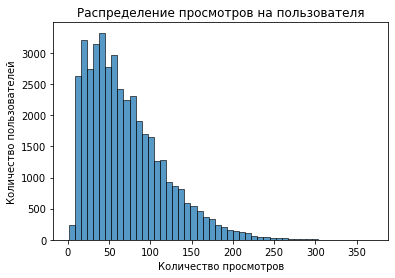

In [7]:
# распределение просмотров
sns.histplot(data=views_distribution, x='views', weights='users', bins=50)
plt.title('Распределение просмотров на пользователя')
plt.xlabel('Количество просмотров')
plt.ylabel('Количество пользователей')
plt.show()

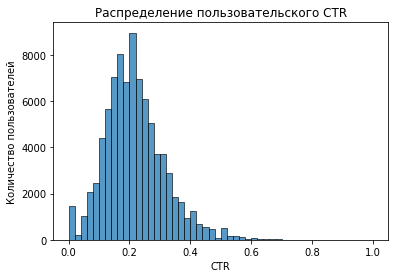

In [8]:
# распределение ctr
sns.histplot(data=ctr_distribution, x='ctr', weights='users', bins=50)
plt.title('Распределение пользовательского CTR')
plt.xlabel('CTR')
plt.ylabel('Количество пользователей')
plt.show()

In [9]:
# кол-во пользователей за период проведения A/A-теста и A/B-теста
q = """
SELECT 
    COUNT(DISTINCT user_id) AS users
FROM {db}.feed_actions
WHERE toDate(time) BETWEEN '2026-09-25' AND '2026-10-08'
"""

n_users_df = pandahouse.read_clickhouse(q, connection=connection)

n_users_df

,users
0,61182


In [10]:
# создание генератора случайных чисел 
rng = np.random.default_rng()

In [11]:
# задаем размер каждой группы
n_users = int(n_users_df['users'][0] // 2)

In [12]:
# задаем кол-во симуляций
n_simulations = 20000

In [13]:
p_values = []

# итерация симуляций
for _ in tqdm(range(n_simulations)):
    group_A_views = rng.choice(a=views_distribution.views, size=n_users, 
                               replace=True, p=views_distribution.p).astype("int64")
    group_B_views = rng.choice(a=views_distribution.views, size=n_users,
                               replace=True, p=views_distribution.p).astype("int64")
    group_B_views = group_B_views + ((1 + rng.binomial(n=1, p=0.5, size=n_users))
                                     * rng.binomial(n=1, p=0.9, size=n_users) * (group_B_views >= 30))
    group_A_ctr = rng.choice(a=ctr_distribution.ctr, size=n_users, 
                             replace=True, p=ctr_distribution.p)
    group_B_ctr = rng.choice(a=ctr_distribution.ctr, size=n_users, 
                             replace=True, p=ctr_distribution.p)
    clicks_A = rng.binomial(n=group_A_views, p=group_A_ctr)
    clicks_B = rng.binomial(n=group_B_views, p=group_B_ctr)
    mask_A = group_A_views >= 30
    mask_B = group_B_views >= 30
    
    p_values.append(stats.ttest_ind(clicks_A[mask_A], 
                                    clicks_B[mask_B], 
                                    equal_var=False).pvalue)
    
power = np.mean(np.array(p_values) < 0.05)

print(f'Мощность эксперимента: {power * 100:.1f}%')

100%|██████████| 20000/20000 [06:44<00:00, 49.49it/s]

Мощность эксперимента: 64.2%
